# Nicholas Alan Gilbert
# Empircal Exercise \# 1
### For Completion of FIN 9777: Data Science in Finance at Baruch College MS Finance

# Navigation

[Set Up](#Setup)

[Import](#Import)
* [Reflect Task 1](#Reflect-Task-1)

[Daily Returns](#Daily-Returns)
* [Reflect Task 2](#Reflect-Task-2)

[Monthly Returns](#Monthly-Returns)
* [Reflect Task 3](#Reflect-Task-3)


# Setup

[Back to Top](#Navigation)

Import necessary libraries:

`import yfinance` for financial data

`import pandas as pd` for data manipulation and handling; `pd` is that standard alias for this library

`import matplotlib.pyplot as plt` for data visualization


In [1]:
import yfinance
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import numpy as np


### Here we will define custom 'helper functions' used throughout the project

In [2]:
def summary_statistics_table(dataframe):
    """
    This helper-function takes a DataFrame of Daily Returns
    with columns of Ticker-names, and rows of dates.
    Returns a DataFrame with summary statistics:
    'Mean', 'Median', 'Standard-Deviation', 'Skewness', 'Kurtosis', 'Min', 'Max'
    utilizing pandas built-in .mean(), .median(), ..., etc. methods
    
    """
    
    columns = dataframe.columns

    index_list = ['Mean', 'Median', 'Standard-Deviation', 'Skewness', 'Kurtosis', 'Min', 'Max']
    
    member_stats = pd.DataFrame(data=None, index=index_list)
    for col in columns:
        rtn:pd.Series = dataframe[col]
        
        mean = rtn.mean()
        median = rtn.median()
        std = rtn.std()
        skew = rtn.skew()
        kurt = rtn.kurt()
        min_rtn = rtn.min()
        max_rtn = rtn.max()



        stats = pd.Series(
            name= col,
            data = [
                mean,
                median,
                std,
                skew,
                kurt,
                min_rtn,
                max_rtn
            ],
            index = index_list,
        )
        member_stats = member_stats.join(stats)

    return member_stats

def return_histograms(dataframe: pd.DataFrame):
    """
    This will display a series of histograms with summary statistics labeled.
    It accepts a pandas DataFrame with Returns data. Row Index of dates. 
    Columns of different tickers.
    It Depends on our helper-function summary_statistics_table()
    """

    stats = summary_statistics_table(dataframe)

    columns = dataframe.columns

    for col in columns:
        plt.grid()
        counts,bins,_ = plt.hist(
            dataframe[col],
            bins = 100,
            color = 'deeppink',
            edgecolor = 'black',
            linewidth = 0.2,
            alpha=0.3
        )
        
        max_occ = counts.max()
        
        #Plot our mean on distribution
        mean = stats[col]['Mean']
        plt.vlines(
            mean,
            ymin=0,
            ymax= 0.95* max_occ,
            color='purple', 
            label=f"Mean={mean:.4f}")
        #Plot +/- standard-deviation
        std = stats[col]['Standard-Deviation']
        std_up = mean + std
        std_down = mean - std
        plt.vlines(
            [std_up, std_down],
            ymin=0,
            ymax= 0.4* max_occ,
            color='blue', 
            alpha=0.7,
            label=rf"$\sigma = \pm${std:.4f}")
        #Plot 2-sigma moves
        std_up2 = mean + std*2
        std_down2 = mean - std*2
        plt.vlines(
            [std_up2, std_down2],
            ymin=0,
            ymax= 0.2* max_occ,
            color='blueviolet', 
            alpha=0.7,
            label=rf"2$\sigma = \pm${std*2:.4f}")
        #Plot 3-sigma moves
        std_up2 = mean + std*3
        std_down2 = mean - std*3
        plt.vlines(
            [std_up2, std_down2],
            ymin=0,
            ymax= 0.1* max_occ,
            color='red',
            alpha=0.7,
            label=rf"3$\sigma =  \pm${std*3:.4f}")

        #Overlay a Bell-Curve

        xmin, xmax = plt.xlim()
        x = np.linspace(xmin, xmax, 100)

        p = st.norm.pdf(x, mean, std)



        bin_width = bins[1] - bins[0]
        scaled_p = p * len(dataframe[col].dropna()) * bin_width
        plt.plot(x,scaled_p, color='black', alpha=0.3, label="Normal-Dist")

        #Clean Up plot and label
        plt.ylabel("# of occurrences")
        plt.xlabel("Return in %-decimal: ie. 1% = 0.01")
        plt.title(f"{col} Return Distribution")
        plt.legend()
        
        plt.show()

# Import

[Back to Top](#Navigation)

Let's instantiate a list of ticker symbols for stocks we would like to perform analysis on

------

### AAPL - Apple Inc - Technology
### TRMD - Torm LLC. - Industrial Shipping
### LMT - Lockheed Marting - Aerospace and Defense
### TGT - Target Corp - Consumer Retail
### DX - Dynex Capital - Real-Estate, mREIT 
### SPY - SPDR S&P 500 ETF Trust - Benchmark Index

We pull in historical data utilizing `yfinance` library. yfinance is referred to as an "API", short for Application-Programatic Interface. yfinance is actually a script that is a glorified webscraper. It is simple and straighforward to use; but one should not depend on it for robust financial applications. For example if you start making high-frequency calls Yahoos server's will restrict your IP address. If Yahoo changes the layout of their webpages then yfinance might break. Nontheless, yfinance is straight-forward and simple to use. It is good-enough for small learning exercises; but it should be noted that it should not be depended on for production use cases.


In [3]:
# Let's instantiate a list of ticker symbols for stocks we would like to perform analysis on

# AAPL - Apple Inc - Technology
# TRMD - Torm LLC. - Industrial Shipping
# LMT - Lockheed Marting - Aerospace and Defense
# TGT - Target Corp - Consumer Retail
# DX - Dynex Capital - Real-Estate, mREIT 
# SPY - SPDR S&P 500 ETF Trust - Benchmark Index

tickers = ['AAPL', 'TRMD', 'LMT', 'TGT', 'DX', 'SPY']

# Now we can grab data on these stocks by calling yfinance methods

yf_tickers = yfinance.Tickers(tickers)

# We call the `.history()` method on our yfinance Tickers object to call histroical data.
# We can pass parameters to the function to define our date range

data = yf_tickers.download(start='1995-01-01', end='2026-08-31')

[*********************100%***********************]  6 of 6 completed


In [4]:
data

Price      Capital Gains       Close                                     \
Ticker               SPY        AAPL         DX         LMT         SPY   
Date                                                                      
1995-01-03           0.0    0.283707   5.055719   10.161205   26.378325   
1995-01-04           0.0    0.291100   4.938149   10.213856   26.504368   
1995-01-05           0.0    0.287403   5.526023   10.354253   26.504368   
1995-01-06           0.0    0.310506   5.643597   10.441998   26.531363   
1995-01-09           0.0    0.304615   5.584808   10.441998   26.558388   
...                  ...         ...        ...         ...         ...   
2026-08-24           0.0  310.339996  12.867857  560.672119  761.578796   
2026-08-25           0.0  309.899994  12.828416  553.098999  764.012756   
2026-08-26           0.0  313.450012  12.700230  562.143005  764.182373   
2026-08-27           0.0  314.579987  12.719950  562.411377  769.189941   
2026-08-28           0.0  319.700012  12.729811  560.383850  767.444275   

Price                             Dividends            ... Stock Splits       \
Ticker             TGT       TRMD      AAPL   DX  LMT  ...          LMT  SPY   
Date                                                   ...                     
1995-01-03    3.117848        NaN       0.0  0.0  0.0  ...          0.0  0.0   
1995-01-04    3.112277        NaN       0.0  0.0  0.0  ...          0.0  0.0   
1995-01-05    3.162387        NaN       0.0  0.0  0.0  ...          0.0  0.0   
1995-01-06    3.140116        NaN       0.0  0.0  0.0  ...          0.0  0.0   
1995-01-09    3.051035        NaN       0.0  0.0  0.0  ...          0.0  0.0   
...                ...        ...       ...  ...  ...  ...          ...  ...   
2026-08-24  169.889999  29.466675       0.0  0.0  0.0  ...          0.0  0.0   
2026-08-25  163.470001  29.308352       0.0  0.0  0.0  ...          0.0  0.0   
2026-08-26  164.039993  28.013830       0.0  0.0  0.0  ...          0.0  0.0   
2026-08-27  165.929993  29.615685       0.0  0.0  0.0  ...          0.0  0.0   
2026-08-28  163.179993  30.379358       0.0  0.0  0.0  ...          0.0  0.0   

Price                     Volume                                       \
Ticker      TGT TRMD        AAPL       DX      LMT       SPY      TGT   
Date                                                                    
1995-01-03  0.0  NaN   103868800     7667   286228    324300  5406000   
1995-01-04  0.0  NaN   158681600     6283   520622    351800  5073600   
1995-01-05  0.0  NaN    73640000    19383  1006036     89800  9802800   
1995-01-06  0.0  NaN  1076622400    23200   663410    448400  9409200   
1995-01-09  0.0  NaN   274086400    21800   481828     36800  8331600   
...         ...  ...         ...      ...      ...       ...      ...   
2026-08-24  0.0  0.0    34673600  5396500  1080600  32430900  6410700   
2026-08-25  0.0  0.0    25869800  4276900  1289700  27422300  7597500   
2026-08-26  0.0  0.0    34024500  3022500   844000  28751600  4660300   
2026-08-27  0.0  0.0    32419200  3593100   823000  34557100  4746000   
2026-08-28  0.0  0.0    38649400  3079500   619000  36744300  3643800   

Price                  
Ticker           TRMD  
Date                   
1995-01-03        NaN  
1995-01-04        NaN  
1995-01-05        NaN  
1995-01-06        NaN  
1995-01-09        NaN  
...               ...  
2026-08-24   738000.0  
2026-08-25   483400.0  
2026-08-26  2102800.0  
2026-08-27   894400.0  
2026-08-28   781700.0  

[7967 rows x 43 columns]

In [5]:
# We are only concerned with daily returns at this point. We can calculate that with the Close Price
price_history = data[['Close', 'Volume']]
price_history

Price            Close                                                 \
Ticker            AAPL         DX         LMT         SPY         TGT   
Date                                                                    
1995-01-03    0.283707   5.055719   10.161205   26.378325    3.117848   
1995-01-04    0.291100   4.938149   10.213856   26.504368    3.112277   
1995-01-05    0.287403   5.526023   10.354253   26.504368    3.162387   
1995-01-06    0.310506   5.643597   10.441998   26.531363    3.140116   
1995-01-09    0.304615   5.584808   10.441998   26.558388    3.051035   
...                ...        ...         ...         ...         ...   
2026-08-24  310.339996  12.867857  560.672119  761.578796  169.889999   
2026-08-25  309.899994  12.828416  553.098999  764.012756  163.470001   
2026-08-26  313.450012  12.700230  562.143005  764.182373  164.039993   
2026-08-27  314.579987  12.719950  562.411377  769.189941  165.929993   
2026-08-28  319.700012  12.729811  560.383850  767.444275  163.179993   

Price                      Volume                                       \
Ticker           TRMD        AAPL       DX      LMT       SPY      TGT   
Date                                                                     
1995-01-03        NaN   103868800     7667   286228    324300  5406000   
1995-01-04        NaN   158681600     6283   520622    351800  5073600   
1995-01-05        NaN    73640000    19383  1006036     89800  9802800   
1995-01-06        NaN  1076622400    23200   663410    448400  9409200   
1995-01-09        NaN   274086400    21800   481828     36800  8331600   
...               ...         ...      ...      ...       ...      ...   
2026-08-24  29.466675    34673600  5396500  1080600  32430900  6410700   
2026-08-25  29.308352    25869800  4276900  1289700  27422300  7597500   
2026-08-26  28.013830    34024500  3022500   844000  28751600  4660300   
2026-08-27  29.615685    32419200  3593100   823000  34557100  4746000   
2026-08-28  30.379358    38649400  3079500   619000  36744300  3643800   

Price                  
Ticker           TRMD  
Date                   
1995-01-03        NaN  
1995-01-04        NaN  
1995-01-05        NaN  
1995-01-06        NaN  
1995-01-09        NaN  
...               ...  
2026-08-24   738000.0  
2026-08-25   483400.0  
2026-08-26  2102800.0  
2026-08-27   894400.0  
2026-08-28   781700.0  

[7967 rows x 12 columns]

<Axes: xlabel='Date'>

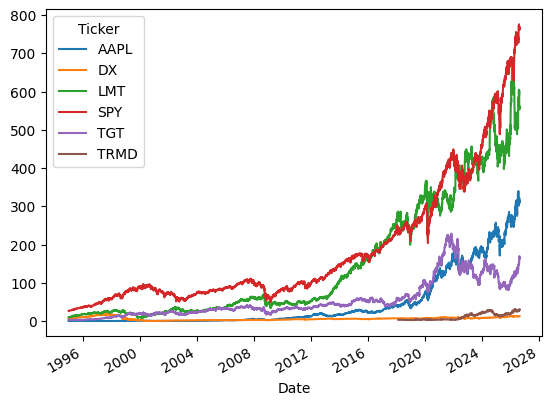

In [6]:
# This is now a Panda's DataFrame object that will be easy to work with:
# Let's take a look at a simple plot of the data with the .plot() method

price_history['Close'].plot()

# Reflect Task 1
[Back to Top](#Navigation)


Right out of the box we can view the price history of our stocks pretty easily. This is a bit of an "apples to oranges" comparison. The fact that one stock's price per share differs from another doesn't tell us much about the performance of that company over time.

We want to make this 'apples to apples', or a common-size comparison of price performance over time. We do that by looking calculated returns.

# Daily Returns

[Back to Top](#Navigation)

## Next we want to compute daily returns. 

We usually use log-returns for heavy-duty quantitative work, with an exploratory analysis such as this we will use simple period returns. Defined below.

Where;

$ r_t = $ return at time period t

$ p_t = $ asset price at time t

$ t = $ time-period eg. daily, weekly, monthly

Asset Return:

$$ r_t = \frac{p_t}{p_{t-1}} - 1$$

Equivalently:

$$ r_t = \frac{p_t - p_{t-1} }{p_{t-1}} $$

I prefer the first expression and I will proof that they are equal:

$$ \frac{p_t - p_{t-1} }{p_{t-1}} = \frac{p_t}{p_{t-1}} - \frac{p_{t-1}}{p_{t-1}} $$
$$ \frac{p_t - p_{t-1} }{p_{t-1}} = \frac{p_t}{p_{t-1}} - 1 $$

Thus our calculation for daily returns:

$$ \frac{r_{\text{today}}} {r_{\text{yesterday}}} - 1 $$

pandas has a method that will do this for us. Let's impliment ourselves and check against pandas' built-in. These little checks are called 'sanity checks' and good proof to the developer that they understand what is going on within their model.

In [7]:
today = price_history['Close']
yesterday = price_history['Close'].shift(1) # This 'shifts' entire columns back by 1-entry.

returns = today / yesterday - 1
pandas_return = price_history['Close'].pct_change(fill_method=None)

In [8]:
#Sanity Check

sanity_check = pandas_return.dropna() == returns.dropna()

sanity_check


Ticker,AAPL,DX,LMT,SPY,TGT,TRMD
Date,,,,,,
2018-02-26,True,True,True,True,True,True
2018-02-27,True,True,True,True,True,True
2018-02-28,True,True,True,True,True,True
2018-03-01,True,True,True,True,True,True
2018-03-02,True,True,True,True,True,True
...,...,...,...,...,...,...
2026-08-24,True,True,True,True,True,True
2026-08-25,True,True,True,True,True,True
2026-08-26,True,True,True,True,True,True


In [9]:
sanity_check.describe()

Ticker,AAPL,DX,LMT,SPY,TGT,TRMD
count,2139,2139,2139,2139,2139,2139
unique,1,1,1,1,1,1
top,True,True,True,True,True,True
freq,2139,2139,2139,2139,2139,2139


## Sanity Check Worked Out 


`.dropna()` ignores missing data that is labelled NaN (Not a Number)

Doing a simple comparison between our calculated values and `pandas` built-in `.pct_change()` method is all `True` values. So we will go ahead and utlize `pandas .pct_change()` to calculate simple returns from here on out.

These little sanity checks are crucial for proving that we understand what is happening and helps us avoid mistakes that could invalidate our analysis downstream.

In [10]:
#We will call our helper-function to output Summary Stats
daily_returns = price_history['Close'].pct_change(fill_method=None)
summary_daily = summary_statistics_table(daily_returns) 


summary_daily

,AAPL,DX,LMT,SPY,TGT,TRMD
Mean,0.001234,0.000565,0.000637,0.000494,0.000719,0.001707
Median,0.000765,0.000000,0.000443,0.000726,0.000316,0.000000
Standard-Deviation,0.026248,0.030053,0.016346,0.011935,0.021066,0.037529
Skewness,-0.421460,1.564136,-0.086732,-0.012480,0.042343,2.983190
Kurtosis,27.746263,57.305824,8.586040,11.436700,11.011960,51.412531
Min,-0.518692,-0.470588,-0.137558,-0.109424,-0.249303,-0.306400
Max,0.332280,0.600000,0.146920,0.145198,0.204256,0.644737


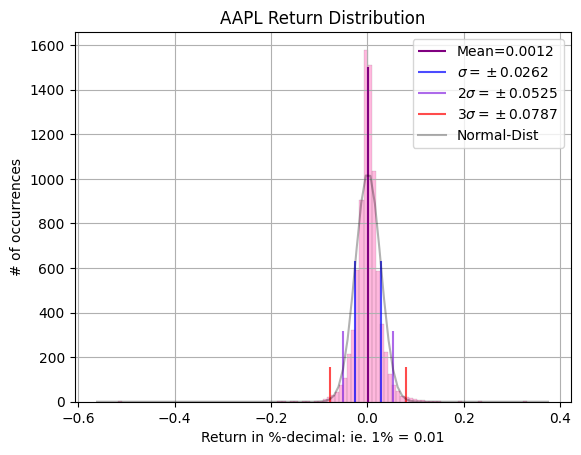

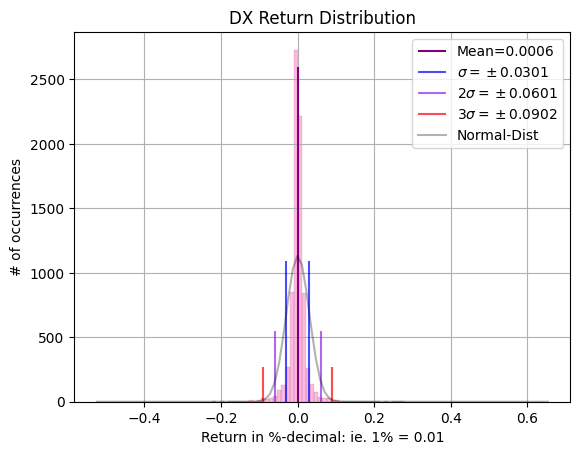

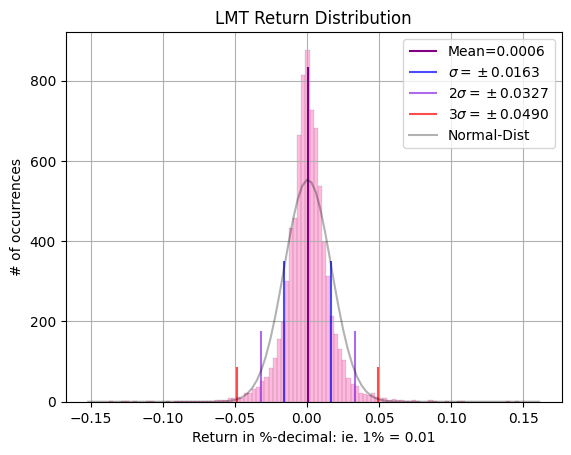

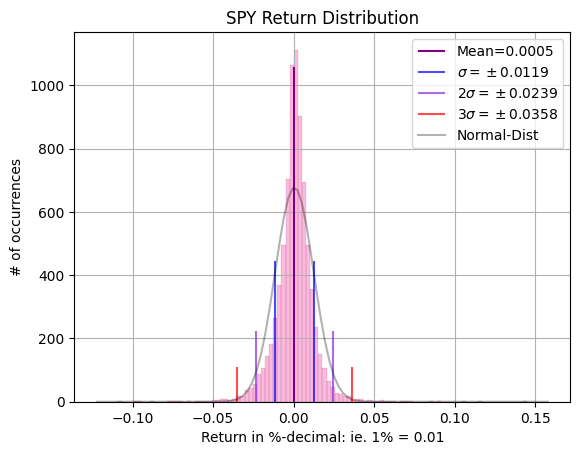

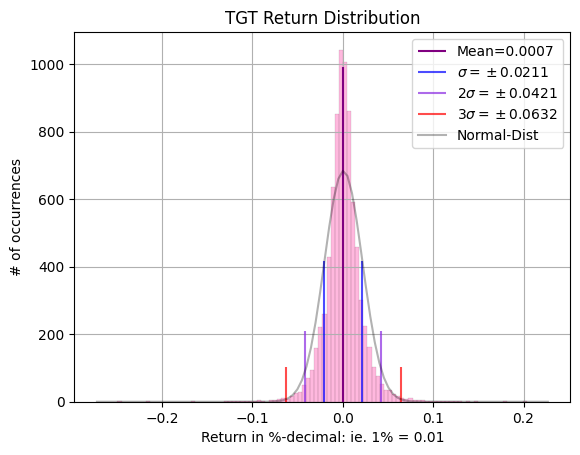

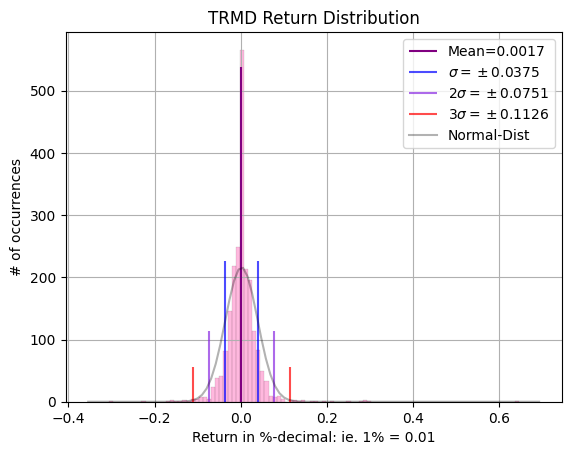

In [11]:
return_histograms(daily_returns)

# Reflect Task 2

## Discussion

We are using real-world data here, so the distributions look a little 'jagged'.
Notice the distribution of stock-returns *almost* follows a standard-normal distribution, *ie.* a bell-curve. Please, read the italicized *almost* as alllllmmmmmmooooooossssst. As asset-returns in financial markets are **NOT** normally distributed!

This bears repeating:

### Financial asset returns do **NOT** follow a normal-distribution

*Assuming* returns follow a standard normal distribution allows a 'starting point' for analysis and discussion. It allows us to say things like *"the average daily return of this stock is 0.05%"* or *volatility*, taken from standard deviation, as the *average price movement* of a stock.

Stock returns exhibit a higher-degree of *fat-tails events*, also known as *black-swan* events. This is evidenced by the extremely high-kurtosis, values between 8-50, where kurtosis of a Standard Normal Distribution = 0

Now that we have framed our normal assumption, we can look at the following.

Let's focus our attention on **AAPL** Apple

Apple is one of the highest growth stocks of the last 2-3 decades, returning +100,000% over this timeframe (1995-2026), yet it's **average daily return** is only ~0.12% with about ~49% of its trading days returning negative. In other words, the expected probability that Apple's stock return will be positive on any given day is just 51%. If you were a short-term trader on a daily time horizon on Apple, your odds of profit are *slightly* better than a 50/50 coin-flip. Apple's growth comes from the slight skew of positive returns and the kurtosis in the positive fat-tail. Those positive gains compounded over decades led to Apple's extraordinary performance, whilst the negative returns are given enough time to recover. The daily average movement is miniscule by comparison to decades of consistent price-perfromance from a stock like Apple. 

## Prompts
* Highest Average Daily Return :

  TRMD, Torm. Had an average daily return of ~0.16% The industrial shipping company beat out Apple suprisingly
  
* Highest Volatility :

  Again Torm with Volatility at ~3.7%
  
* Is Highest-Return ?= Highest-Vol. :

  Yes. 
  
* Risk-Return

  This follows the notion that high-reward $\implies$ high-risk

[Back to Top](#Navigation)

# Monthly Returns

In [12]:
# Here We just pull a snapshot of the price for each month. Should default to the month's beginning price
monthly_ticks = data = yf_tickers.history(start='1995-01-01', end='2026-08-31', interval='1mo')
monthly_ticks = monthly_ticks['Close']
monthly_ticks

[*********************100%***********************]  6 of 6 completed


Ticker,AAPL,DX,LMT,SPY,TGT,TRMD
Date,,,,,,
1995-01-01,0.298493,6.290259,10.108562,27.134573,3.056603,NaN
1995-02-01,0.292827,7.759948,10.980509,28.241911,3.158041,NaN
1995-03-01,0.261320,7.341212,12.191541,29.028393,3.202834,NaN
1995-04-01,0.283560,7.762429,13.315583,29.888281,3.006857,NaN
1995-05-01,0.308971,8.905732,13.800618,31.074053,3.194707,NaN
...,...,...,...,...,...,...
2026-04-01,270.866638,12.742678,511.437775,715.037720,127.556534,29.624537
2026-05-01,311.791107,12.410752,523.760437,752.667114,126.102097,25.368906
2026-06-01,289.110657,12.593642,506.328247,744.920227,129.615143,24.269960


# Monthly-Tick Returns

In [13]:
monthly_tick_return = monthly_ticks.pct_change()
summary_month_tick = summary_statistics_table(monthly_tick_return)
summary_month_tick

,AAPL,DX,LMT,SPY,TGT,TRMD
Mean,0.025378,0.008867,0.013182,0.009799,0.013834,0.028870
Median,0.027662,0.007103,0.011636,0.014113,0.012291,0.024620
Standard-Deviation,0.114828,0.112861,0.070618,0.043421,0.081976,0.120308
Skewness,-0.287919,0.357445,-0.395238,-0.566226,0.103426,0.460779
Kurtosis,2.493012,15.226930,3.767853,0.915856,0.617801,0.461175
Min,-0.577437,-0.722222,-0.388145,-0.165187,-0.289100,-0.239544
Max,0.453783,0.750000,0.311266,0.126983,0.266949,0.371545


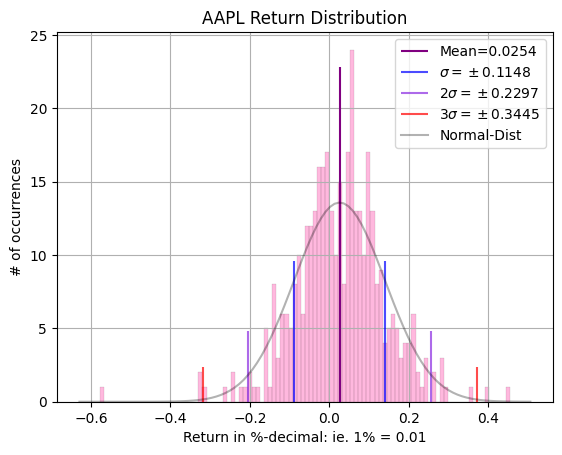

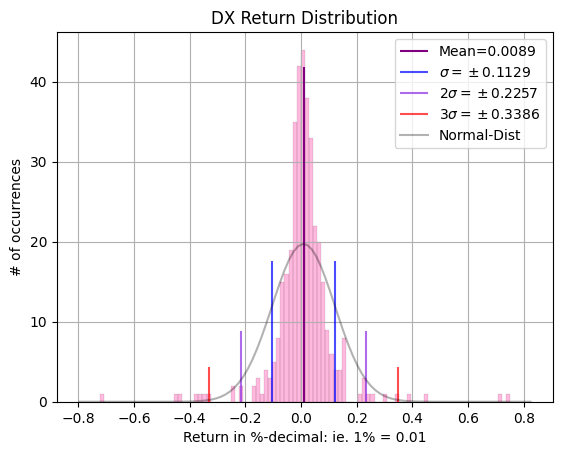

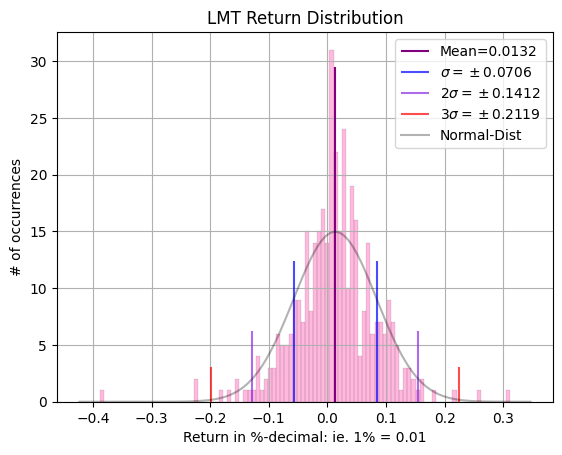

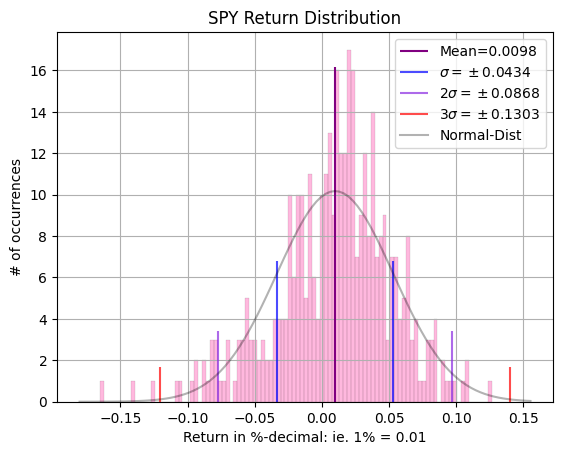

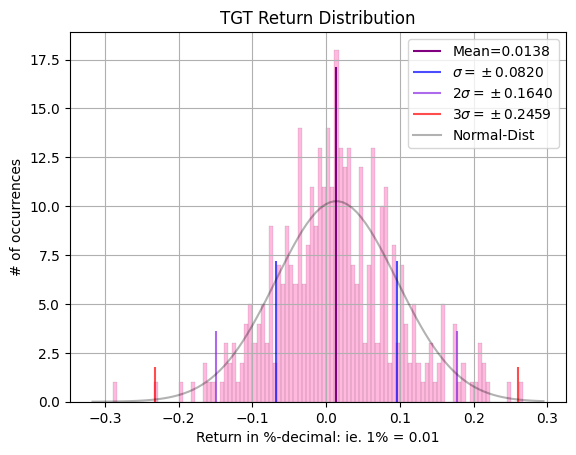

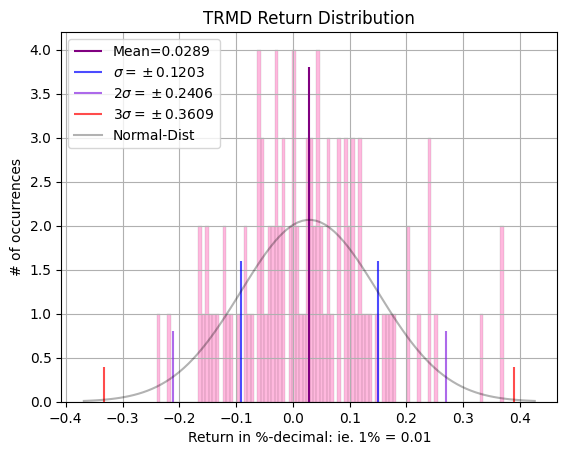

In [14]:
return_histograms(monthly_tick_return)

## Compare to Daily 

Rescaled to monthly figure by just a simple times 21 (avg. trading days/month) with volatility scaled by $\sqrt{21}$

ignore the higher moments with simple rescaling

In [15]:
daily_returns.skew(), daily_returns.kurt()

(Ticker
 AAPL   -0.421460
 DX      1.564136
 LMT    -0.086732
 SPY    -0.012480
 TGT     0.042343
 TRMD    2.983190
 dtype: float64,
 Ticker
 AAPL    27.746263
 DX      57.305824
 LMT      8.586040
 SPY     11.436700
 TGT     11.011960
 TRMD    51.412531
 dtype: float64)

In [16]:
daily_returns.std() * np.sqrt(21)

Ticker
AAPL    0.120281
DX      0.137720
LMT     0.074907
SPY     0.054694
TGT     0.096538
TRMD    0.171981
dtype: float64

In [17]:
daily_to_month_summary = summary_statistics_table(daily_returns *21 )
daily_to_month_summary.loc[['Mean']]

,AAPL,DX,LMT,SPY,TGT,TRMD
Mean,0.025919,0.011856,0.013384,0.010384,0.015104,0.035841


# Reflect Task 3

[Back to Top](#Navigation)

Daily Volatility (Standard-Deviation) rescaled to monthly by $\sqrt{21}$ is higher then the monthly sample $\sigma$ volatility. This makes sense as the daily figure captures more *'noise'* of the stock moving back and forth. By *'zooming out'* to monthly, we *smooth-out* the return profile, which has the effect of producing a lower volatility measure. Since the asset price can go up and down multiple times over the course of the month, some of those little up & down 'wiggles' are 'ignored' by the larger time sampling size.

Perhaps best illustrated with the following visualization, of daily return and monthly return plotted together for the same security (see below)



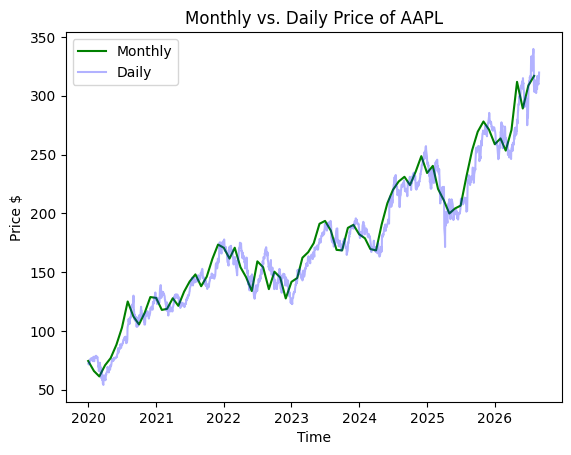

In [18]:
plt.plot(monthly_ticks.loc['2020':'2026']['AAPL'],color='green',label='Monthly')
plt.plot(today.loc['2020':'2026']['AAPL'],color='blue', alpha=0.3, label='Daily')
plt.legend()
plt.title('Monthly vs. Daily Price of AAPL')
plt.xlabel('Time')
plt.ylabel('Price $')
plt.show()

In [31]:
for ticker in daily_returns.columns:
    stock_return = daily_returns[ticker]
    three_sigma = stock_return.std() * 3
    three_sigma_moves = stock_return.where(stock_return.abs() > three_sigma).dropna()
    print(three_sigma_moves)
    

Date
1995-01-06    0.080386
1995-03-14   -0.081968
1995-09-15   -0.103124
1995-12-18   -0.085108
1996-01-05    0.085151
                ...   
2020-07-31    0.104689
2020-09-03   -0.080061
2022-11-10    0.088975
2025-04-03   -0.092456
2025-04-09    0.153289
Name: AAPL, Length: 114, dtype: float64
Date
1995-01-05    0.119048
1995-01-13    0.103448
1998-09-09   -0.134147
1998-10-05   -0.176923
1998-10-06   -0.121495
                ...   
2020-03-30   -0.096991
2020-04-01   -0.109195
2020-04-06    0.112798
2020-04-08    0.173756
2022-04-27    0.095598
Name: DX, Length: 152, dtype: float64
Date
1995-04-24    0.053572
1995-06-19    0.049383
1997-04-04    0.055205
1997-10-27   -0.052191
1998-01-07    0.051768
                ...   
2025-01-28   -0.091803
2025-03-21   -0.057934
2025-04-04   -0.049760
2025-07-22   -0.108115
2026-07-23    0.105432
Name: LMT, Length: 131, dtype: float64
Date
1997-10-27   -0.072474
1997-10-28    0.057706
1998-08-04   -0.038743
1998-08-27   -0.047073
1998-08-31  

In [33]:
for ticker in daily_returns.columns:
    stock_return = daily_returns[ticker]
    four5_sigma = stock_return.std() * 4.5
    four5_sigma_moves = stock_return.where(stock_return.abs() > three_sigma).dropna()
    print(four5_sigma_moves)
    

Date
1996-07-18    0.237035
1997-01-06   -0.178160
1997-07-11    0.146225
1997-08-06    0.332280
1998-01-02    0.238088
1998-01-06    0.192916
1998-10-09    0.139957
1999-04-27    0.117558
1999-09-21   -0.124110
1999-10-14    0.142996
2000-03-01    0.136858
2000-09-29   -0.518692
2000-12-06   -0.158088
2001-04-18    0.117155
2001-04-19    0.128566
2001-07-18   -0.171712
2002-06-19   -0.150372
2002-07-17   -0.124862
2003-05-05    0.113492
2004-07-15    0.113253
2004-10-14    0.131573
2006-07-20    0.118299
2008-09-29   -0.179195
2008-10-13    0.139050
2008-11-24    0.125575
2013-01-24   -0.123558
2020-03-13    0.119808
2020-03-16   -0.128647
2025-04-09    0.153289
Name: AAPL, dtype: float64
Date
1995-01-05    0.119048
1998-09-09   -0.134147
1998-10-05   -0.176923
1998-10-06   -0.121495
1998-10-07   -0.159575
                ...   
2020-03-24   -0.214351
2020-03-25    0.146370
2020-03-26    0.347293
2020-04-06    0.112798
2020-04-08    0.173756
Name: DX, Length: 97, dtype: float64
Date
1